---

<br>

# MODULE 4: SIMPLE LINEAR REGRESSION

<br>

---

In this section we'll build our first **simple linear regression** models in Python and learn about the `metrics` and `statistical tests` that help evaluate their quality and output.

<br>

## Topics We'll Cover

>- Linear Regression Model
>
>- Least Squared Error
>
>- Regression in Python
>
>- Making Predictions
>
>- Evaluation Metrics

<br>

## Goals for This Section

>- Introduce the linear regression equation
>
>- Visualize the least squared error method for finding the line of best fit
>
>- Build linear regression models in Python and use them to make predictions for the target
>
>- Interpret the model summary statistics and use them to evaluate the model's accuracy
>

<br><br>

<br><br>

---

## Simple Linear Regression

**Simple Linear Regression** models use a single feature to predict the target

>- This is achieved by fitting a line through the data points in a scatterplot (*like an lmplot*)

<br><br>

---

# Linear Regression Model

<br>

The **linear regression model** is an equation that best describes a linear relationship.

<br>

## Predicted value (the model's estimate)

$$\LARGE\hat{y} = \beta_0 + \beta_1 x$$

>
>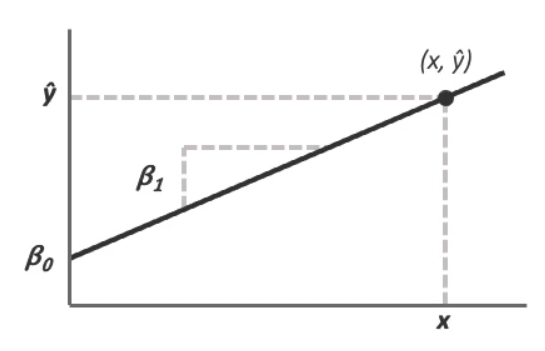
>
>
>- $\hat{y}$ — the **predicted** value for the target
>- $\beta_0$ — the **y-intercept**
>- $\beta_1$ — the **slope** of the relationship
>- $x$ — the value for the feature

<br>

## Actual value (what we really observe)

$$\LARGE y = \beta_0 + \beta_1 x + \epsilon$$

>
>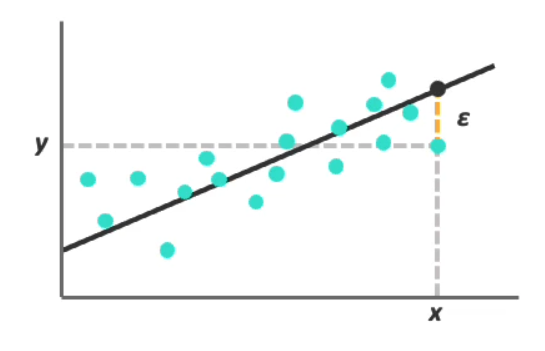
>

>- $y$ — the **actual** value for the target
>- $\epsilon$ — the **error**, or **residual**, caused by the difference between the actual and predicted values
 
<br><br>

<br><br>

---

# Least Squared Error

<br>

The **Least Squared Error** method finds the line that best fits through the data

>- It works by solving for the line that **minimizes the sum of squared error**
>
>- The equation that minimizes error can be solved with **linear algebra**
>

## Why Squared Error?

>- Squaring the residuals converts them into **positive values**, and prevents positive and negative distances from cancelling each other out (*this makes the algebra to solve the line muchj easier*)
>
>- One drawback of squarred errors is that outliers can significantly impact the line.
>

**NOTE: Ordinary Least Squares (OLS)** is another term for traditional linear regression. There are other frameworks for linear regression that don't use least squared error, but they are rarely used.

>---
>
> SOME EXAMPLE OF SUM OF SQUARED ERRORS WITH DIFFERENT EQUATIONS
>
>---
>
>
>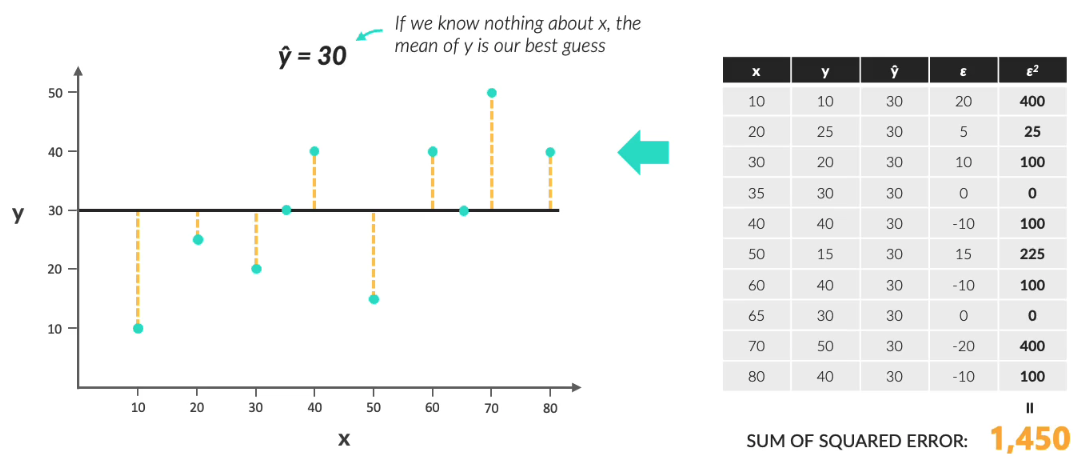
>
>---
>
>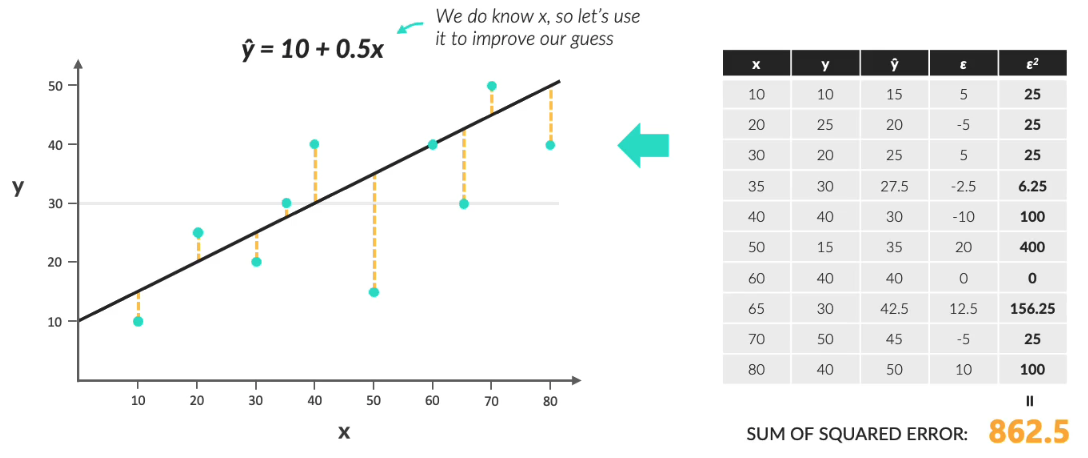
>
>---
>
>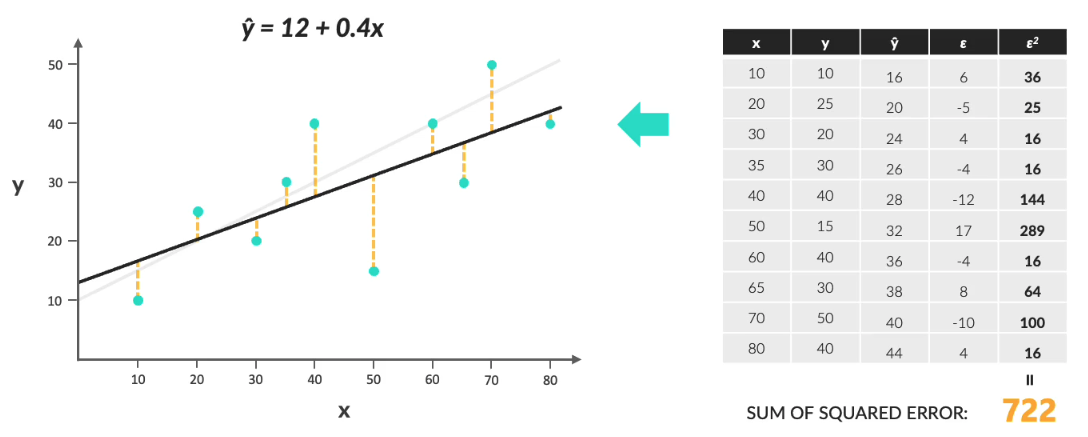
>
>---

<br><br>

---

# Linear Regression in Python

<br>

There are two Python libraries used to fit Linear Regression Models:

>---
>
>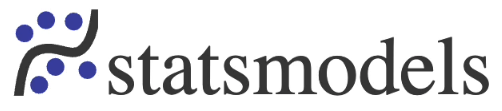
>
>- **It is ideal if you goal is inference**
>- It has a similar output to other tools (*SAS, R, Excel*)
>- It has easy access to dozens of statistical tests
>- It's harder to leverage in production ML
>
>---
>
>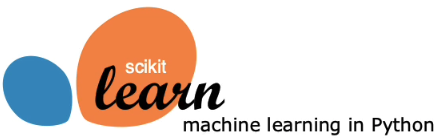
>
>- **It is ideal if your goal is prediction**
>- It is the most popular ML library in Python
>- It has various models for easy comparison
>- It is designed to be deployed to production
>
>---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm
from sklearn.linear_model import LinearRegression

In [2]:
diamonds = pd.read_csv('../datasets/Diamonds Prices2022.csv')
diamonds.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [3]:
# let's create our single feature "carat" and the target "price"
X = diamonds[['carat']] # this must be a matrix (2D)
y = diamonds['price'] # this must be a vector (1D)

In [4]:
# First we will work with Statsmodels
sm.OLS(y, X).fit().summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:                  price   R-squared (uncentered):                   0.881
Model:                            OLS   Adj. R-squared (uncentered):              0.881
Method:                 Least Squares   F-statistic:                          4.004e+05
Date:                Tue, 03 Nov 2026   Prob (F-statistic):                        0.00
Time:                        20:06:52   Log-Likelihood:                     -4.8464e+05
No. Observations:               53943   AIC:                                  9.693e+05
Df Residuals:                   53942   BIC:                                  9.693e+05
Df Model:                           1                                                  
Covariance Type:            nonrobust                                                  
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
carat       5666.2131      8.955    632.764      0.000    5648.662    5683.764
==============================================================================
Omnibus:                    26112.003   Durbin-Watson:                   0.344
Prob(Omnibus):                  0.000   Jarque-Bera (JB):           146451.869
Skew:                           2.340   Prob(JB):                         0.00
Kurtosis:                       9.577   Cond. No.                         1.00
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [5]:
model = LinearRegression(fit_intercept=False)
model.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",False
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[5666.21]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['carat']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float,0
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [6]:
model.coef_

array([5666.21312432])

In [7]:
model.intercept_

0.0

<br><br>

---

# Linear Regression in Statsmodels

<br>

>---
>
>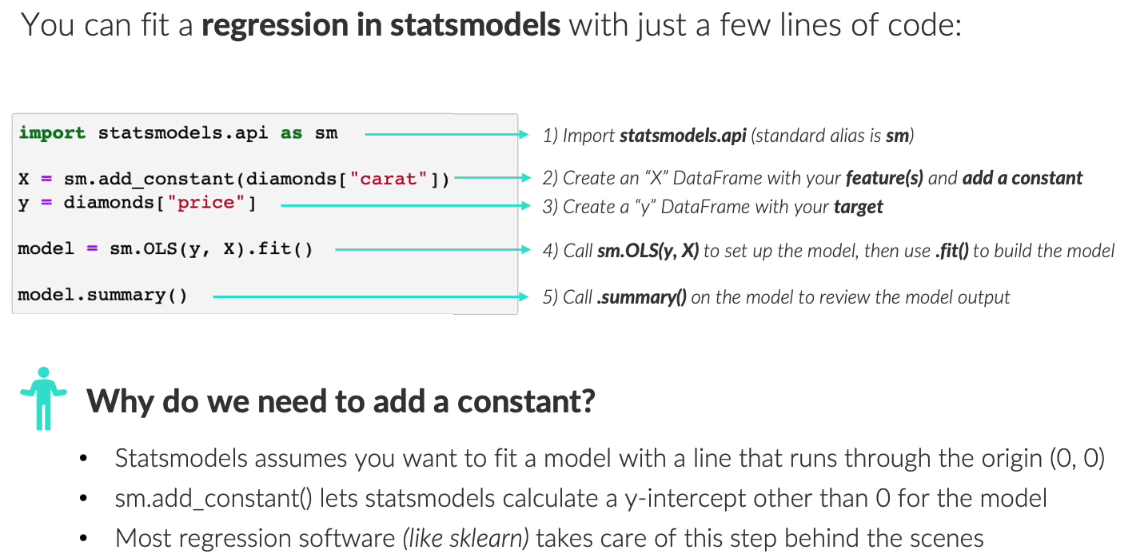
>
>---
>
>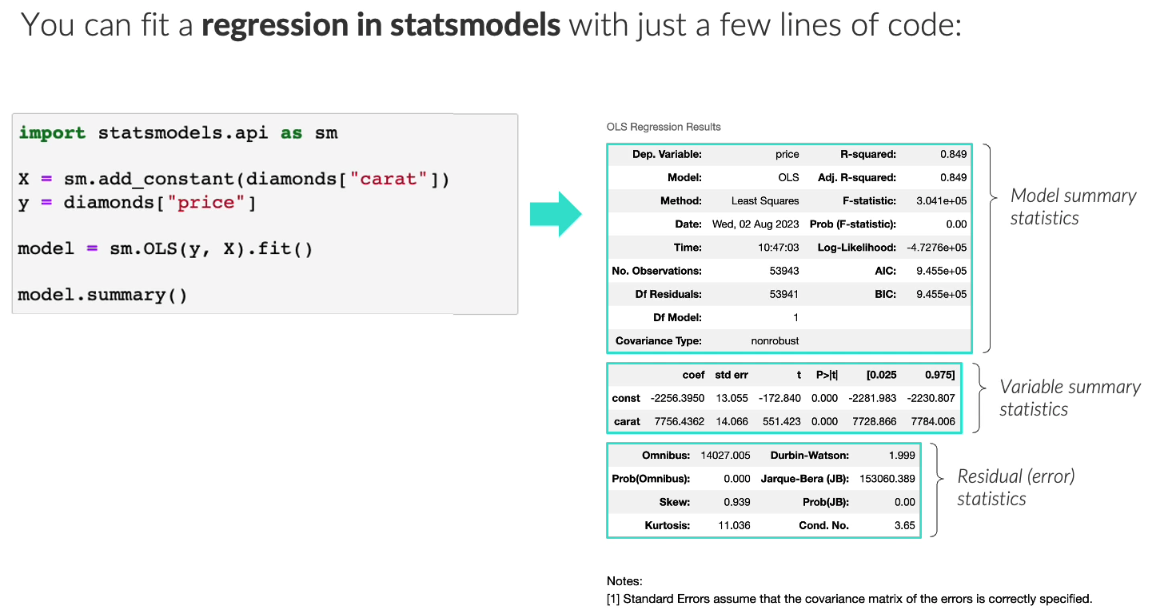
>
>---

In [10]:
X = sm.add_constant(diamonds[['carat']])
y = diamonds['price']

model_s = sm.OLS(y, X).fit()
model_s.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  price   R-squared:                       0.849
Model:                            OLS   Adj. R-squared:                  0.849
Method:                 Least Squares   F-statistic:                 3.041e+05
Date:                Tue, 03 Nov 2026   Prob (F-statistic):               0.00
Time:                        20:39:32   Log-Likelihood:            -4.7276e+05
No. Observations:               53943   AIC:                         9.455e+05
Df Residuals:                   53941   BIC:                         9.455e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -2256.3950     13.055   -172.840      0.000   -2281.983   -2230.807
carat       7756.4362     14.066    551.423      0.000    7728.866    7784.006
==============================================================================
Omnibus:                    14027.005   Durbin-Watson:                   0.986
Prob(Omnibus):                  0.000   Jarque-Bera (JB):           153060.389
Skew:                           0.939   Prob(JB):                         0.00
Kurtosis:                      11.036   Cond. No.                         3.65
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [11]:
X

,const,carat
0,1.0,0.23
1,1.0,0.21
2,1.0,0.23
3,1.0,0.29
4,1.0,0.31
...,...,...
53938,1.0,0.86
53939,1.0,0.75
53940,1.0,0.71
53941,1.0,0.71


<br><br>

---

# Interpreting the Model

<br>

>---
>
>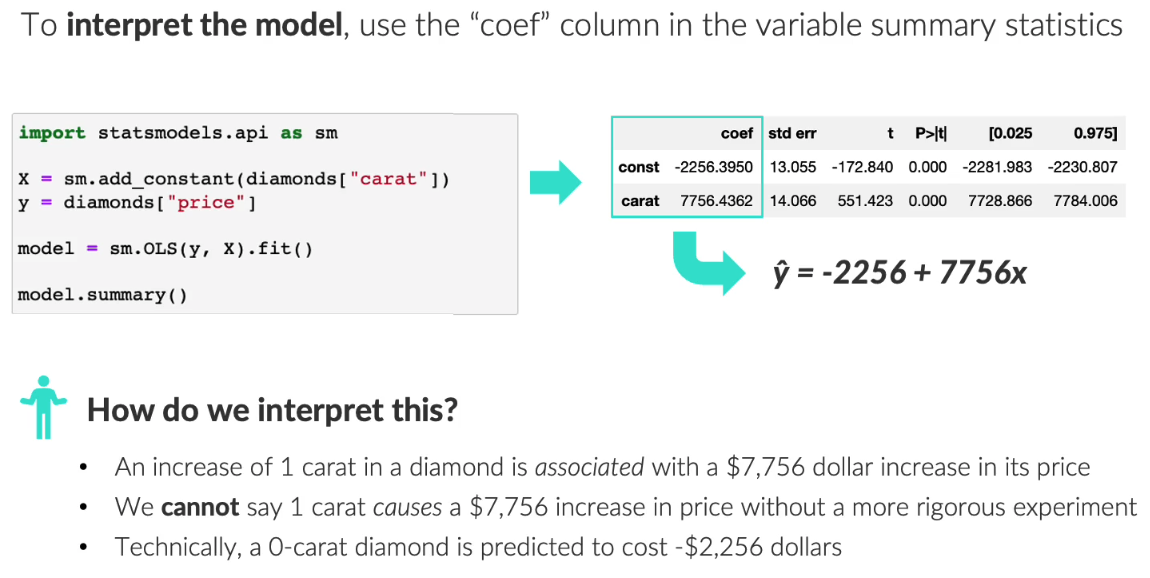
>
>---

<br><br>

---

# Making Predictions

<br>

In [12]:
# We'll use the same fitted model on "Statsmodels"
# Example: use a constant of 1, and a carat value of 2
model_s.predict([1, 2])

array([13256.47727148])

In [13]:
# We can configure the carat values we want to predict. Without adding the Constant of 1
new_diamonds = pd.DataFrame({'carat':[0, 0.1, 0.3, 0.5, 1, 2, 3, 4, 5]})
new_diamonds

,carat
0,0.0
1,0.1
2,0.3
3,0.5
4,1.0
5,2.0
6,3.0
7,4.0
8,5.0


In [14]:
# ...but we'll need to use the ".add_constant" to let Statsmodels add the constant for us
model_s.predict(sm.add_constant(new_diamonds))

0    -2256.395048
1    -1480.751432
2       70.535800
3     1621.823032
4     5500.041112
5    13256.477271
6    21012.913431
7    28769.349590
8    36525.785750
dtype: float64

>---
>
>NOTE: As we can see on the output from the prediction of our "model_s" model.
>
>This models is not perfect yet. Because when we want to predict a carat from 0 to 0.1, **the model predicts NEGATIVE USD, which is not correct.**
>
>---

<br><br>

---

# R-Squared

<br>

>---
>
>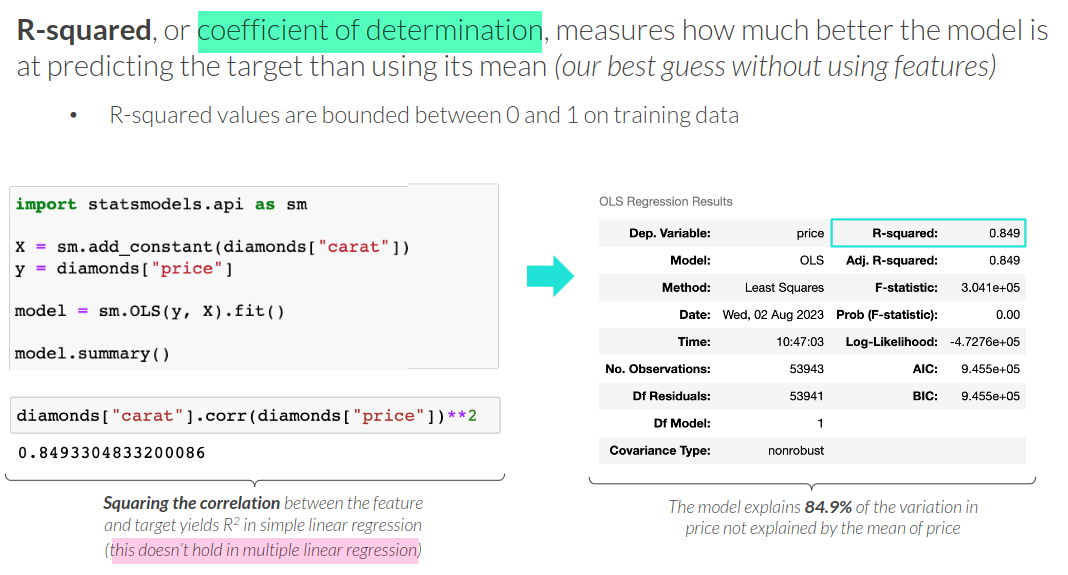
>
>---
>
>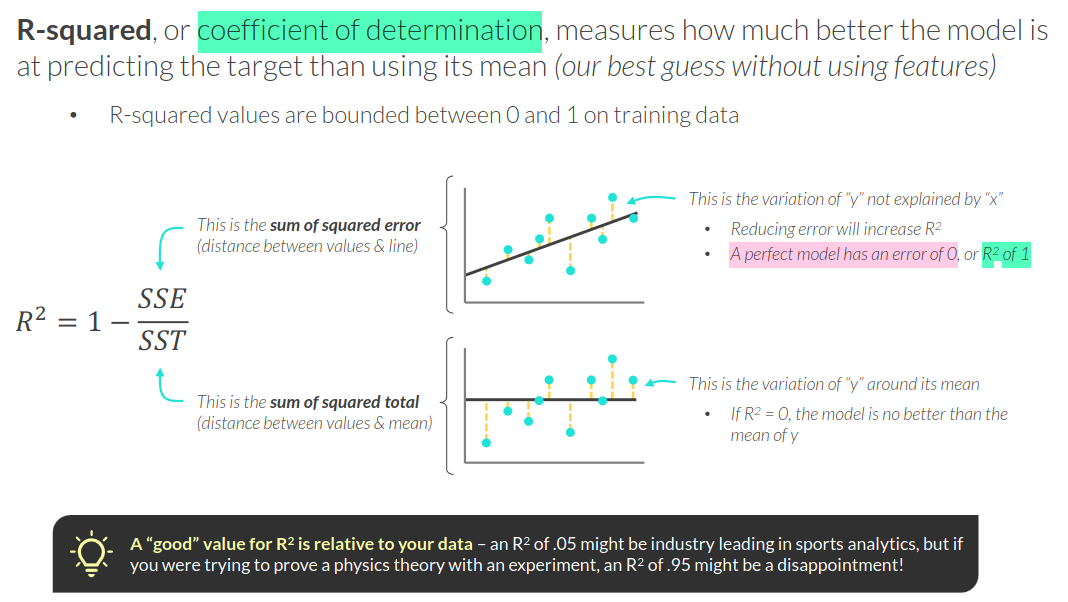
>
>---

<br><br>

---

# Hypothesis Test

<br>